# KNN e Árvores de Decisão: Fundamentos e Implementação

**Disciplina:** Métodos e Aplicações de IA  
**Professor:** Carlos Eduardo Leal de Castro  
**Faculdade Ibmec São Paulo — Faria Lima**

**Entrega:** 02/10 — Resolva todos os exercícios marcados com `#TODO` e entregue o notebook executado.

---

## Como usar este notebook

Este material alterna três tipos de atividade:

1. **Explicações e exemplos guiados**: código já implementado para observar o comportamento do algoritmo;
2. **Implementações do zero**: exercícios em NumPy para entender o mecanismo interno;
3. **Exercícios com scikit-learn**: seleção de hiperparâmetros, avaliação e interpretação dos resultados.

Os `#TODO` foram mantidos apenas onde a implementação faz parte do objetivo de aprendizagem. Visualizações mais mecânicas — como a construção de uma fronteira de decisão — aparecem prontas e comentadas para que o foco fique na **interpretação do modelo**.

## Datasets

Todos os datasets vêm do **scikit-learn** (`sklearn.datasets`): Iris, Wine, Breast Cancer e Diabetes. **Não é necessário baixar nada fora do notebook.**

> **Instruções gerais:** execute as células em ordem. Onde houver `#TODO`, complete o código e/ou responda em texto na célula markdown indicada. Justifique respostas discursivas com base nos resultados obtidos.


## 1. Setup e dados

Vamos importar os pacotes e carregar os datasets que usaremos ao longo do notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_wine, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, mean_squared_error, r2_score)

np.random.seed(42)

# Datasets
iris = load_iris()
wine = load_wine()
cancer = load_breast_cancer()
diabetes = load_diabetes()

print("Iris:        ", iris.data.shape, "| classes:", iris.target_names)
print("Wine:        ", wine.data.shape, "| classes:", wine.target_names)
print("Breast Cancer:", cancer.data.shape, "| classes:", cancer.target_names)
print("Diabetes (regressão):", diabetes.data.shape)

Iris:         (150, 4) | classes: ['setosa' 'versicolor' 'virginica']
Wine:         (178, 13) | classes: ['class_0' 'class_1' 'class_2']
Breast Cancer: (569, 30) | classes: ['malignant' 'benign']
Diabetes (regressão): (442, 10)


# Parte 1 — KNN (K-Nearest Neighbors)

## 1.1 Intuição: aprender olhando para os vizinhos

O KNN é um exemplo clássico de **aprendizado baseado em instância** (*instance-based learning*), também chamado de **lazy learning**.

Em vez de aprender uma equação ou uma árvore durante `fit`, ele guarda os exemplos de treinamento. Quando chega uma nova amostra, a pergunta passa a ser:

> **Quais exemplos conhecidos estão mais próximos desta nova amostra?**

Para classificar um novo ponto $x$:

1. escolha $k$, o número de vizinhos;
2. calcule a distância de $x$ para os pontos de treinamento;
3. selecione os $k$ mais próximos;
4. use a **classe majoritária** entre eles.

Na regressão, o passo 4 muda: em vez de votação, usamos tipicamente a **média** dos valores-alvo dos vizinhos.

### Um exemplo mental

Imagine que queremos classificar uma flor e os cinco exemplos mais próximos têm classes:

$$
[0,\;0,\;0,\;1,\;1].
$$

Para $k=5$, a predição será a classe **0**, pois ela recebeu 3 dos 5 votos.  
Se usássemos $k=1$, apenas o vizinho mais próximo decidiria — o modelo ficaria muito mais sensível a ruído.

---

## 1.2 Distância e escala

A distância Euclidiana entre dois vetores $a$ e $b$ é

$$
d(a,b)=\sqrt{\sum_i(a_i-b_i)^2}.
$$

Outras métricas comuns:

- **Manhattan** ($p=1$): $\sum_i |a_i-b_i|$;
- **Minkowski**: generaliza Euclidiana e Manhattan.

### Por que a escala importa tanto?

Considere duas features:

- idade: varia aproximadamente entre 18 e 80;
- renda anual: varia entre 2.000 e 100.000.

Uma diferença de **R$ 10.000** na renda domina numericamente uma diferença de **10 anos** na idade. Para um algoritmo baseado em distância, isso pode fazer a renda decidir quase sozinha quem é “vizinho”.

Por isso, quando as features estão em escalas diferentes, é prática padrão aplicar algo como `StandardScaler`.

> **Regra importante:** o `scaler` é ajustado (`fit`) **somente com o conjunto de treino**. No teste, usamos apenas `transform`. Ajustar o scaler com o teste introduziria *data leakage*.

---

## 1.3 O hiperparâmetro $k$: viés e variância

O valor de $k$ controla o quanto a decisão é local:

- **$k$ pequeno**: decisões muito locais, maior variância e maior risco de *overfitting*;
- **$k$ grande**: decisões mais suavizadas, maior viés e maior risco de *underfitting*.

Não existe um $k$ universalmente melhor. Ele deve ser escolhido com **validação**.

### Custo computacional

Na implementação ingênua, prever uma amostra exige comparar esse ponto com os $n$ exemplos de treino, cada um com $d$ features:

$$
O(n\cdot d).
$$

Bibliotecas podem usar estruturas como KD-Tree ou Ball-Tree quando a geometria e a dimensionalidade permitem, mas em dimensões altas a busca por vizinhos tende a perder eficiência.

## 1.4 Implementação do zero com NumPy

Agora vamos implementar os componentes essenciais do KNN. Aqui os `#TODO`s são deliberados: calcular distâncias, ordenar vizinhos e realizar a votação são justamente o mecanismo do algoritmo.


### Exercício 1 — Distâncias com NumPy (guiado)

Complete a função abaixo para calcular a **distância Euclidiana** entre um ponto `x` e **todas** as linhas de uma matriz `X` de uma só vez (vetorizado, sem `for`).

Dica: `np.sum((X - x)**2, axis=1)` calcula as distâncias ao quadrado; você pode evitar a raiz quadrada se só quiser **ordenar** (por quê?).

In [ ]:
def euclidean_distances(X, x):
    """
    Retorna um array com a distância euclidiana de x a cada linha de X.

    Parâmetros
    ----------
    X : np.ndarray de shape (n_amostras, n_features)
    x : np.ndarray de shape (n_features,)

    Retorno
    -------
    np.ndarray de shape (n_amostras,)
    """
    # ✅ RESPOSTA — Exercício 1
    # (X - x) usa broadcasting: (n, d) - (d,) -> (n, d). A soma no eixo 1 colapsa as
    # features e deixa um valor por amostra. Nenhum laço em Python.
    return np.sqrt(np.sum((X - x) ** 2, axis=1))

# Por que a raiz é dispensável para ORDENAR: a raiz quadrada é estritamente crescente
# em [0, ∞), então argsort(d²) == argsort(d). Guardamos a raiz aqui porque a função é
# usada também para reportar distâncias, e aí a unidade importa.

# Teste rápido — quando funcionar, deve imprimir [5.0, 0.0]
try:
    X_teste = np.array([[3.0, 4.0], [0.0, 0.0]])
    print(euclidean_distances(X_teste, np.array([0.0, 0.0])))
except NotImplementedError as e:
    print("Pendente:", e)

### Implementação do KNN (classificação) — parte guiada, parte exercício

Abaixo está o esqueleto de uma classe `KNNClassifier` no estilo scikit-learn (com `fit` e `predict`). Parte está pronta; complete os `#TODO`.

In [ ]:
from collections import Counter

class KNNClassifier:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        # KNN é "lazy": fit apenas memoriza os dados
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def _predict_one(self, x):
        # 1) distâncias de x a todos os pontos de treino
        dists = euclidean_distances(self.X_train, x)

        # ✅ RESPOSTA — 2) índices dos k vizinhos mais próximos
        idx_vizinhos = np.argsort(dists)[:self.k]

        # ✅ RESPOSTA — 3) votação majoritária entre os rótulos dos vizinhos
        rotulos = self.y_train[idx_vizinhos]
        vencedor = Counter(rotulos).most_common(1)[0][0]

        return vencedor

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x) for x in X])

# Nota sobre empates: Counter.most_common devolve, em caso de empate, o rótulo que
# apareceu primeiro na contagem — determinístico, mas arbitrário. É a razão prática
# de se preferir k ímpar em problemas binários.

### Testando seu KNN no Iris

Vamos usar apenas **duas features** do Iris. O algoritmo não exige duas dimensões; essa escolha é didática, pois mais adiante conseguiremos visualizar o espaço de decisão em um plano.

Observe também a sequência correta de pré-processamento:

1. separar treino e teste;
2. ajustar o `StandardScaler` apenas no treino;
3. transformar treino e teste com os parâmetros aprendidos no treino.


In [4]:
X = iris.data[:, [0, 2]]  # sepal length, petal length
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)  # note: só transform no teste!

knn = KNNClassifier(k=5)
knn.fit(X_train_s, y_train)
try:
    y_pred = knn.predict(X_test_s)
    print("Acurácia (seu KNN):", accuracy_score(y_test, y_pred))
except Exception as e:
    print("Complete os TODOs da classe KNNClassifier. Erro:", e)

Complete os TODOs da classe KNNClassifier. Erro: Implemente a distância euclidiana


## 1.5 KNN com scikit-learn

Depois de entender a mecânica, vamos usar `KNeighborsClassifier`, a implementação pronta do scikit-learn.

Aqui usaremos o dataset **Wine**, com 13 features. Primeiro comparamos o KNN sem padronização e depois com `StandardScaler`.

O objetivo não é concluir que “normalizar sempre melhora qualquer modelo”, mas observar que, para um método cuja noção de similaridade depende diretamente de distâncias, **a escala das variáveis participa da definição de vizinhança**.


In [3]:
X_w, y_w = wine.data, wine.target
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_w, y_w, test_size=0.3, random_state=42, stratify=y_w)

from sklearn.neighbors import KNeighborsClassifier

# Sem normalização
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(Xw_train, yw_train)
print("Acurácia sem normalizar:", accuracy_score(yw_test, knn_raw.predict(Xw_test)))

# Com normalização
sc = StandardScaler()
knn_std = KNeighborsClassifier(n_neighbors=5)
knn_std.fit(sc.fit_transform(Xw_train), yw_train)
print("Acurácia com StandardScaler:", accuracy_score(yw_test, knn_std.predict(sc.transform(Xw_test))))

Acurácia sem normalizar: 0.7222222222222222
Acurácia com StandardScaler: 0.9444444444444444


## 1.6 O que é uma fronteira de decisão?

Um classificador divide o espaço das features em **regiões de decisão**.

Em duas dimensões, podemos imaginar cada possível combinação $(x_1,x_2)$ como um ponto no plano. Para cada ponto, perguntamos ao modelo:

> **“Se uma amostra aparecesse exatamente aqui, qual classe você preveria?”**

Ao colorir o plano de acordo com essa predição, obtemos as regiões de decisão. A **fronteira de decisão** é a região de transição entre cores — isto é, onde a classe prevista muda.

### Como o gráfico é construído?

1. criamos uma grade densa de pontos com `np.meshgrid`;
2. empilhamos as coordenadas da grade;
3. pedimos `predict` para todos esses pontos;
4. recolocamos as previsões no formato da grade;
5. colorimos as regiões com `contourf`;
6. sobrepomos os exemplos reais de treino e teste.

A fronteira **não é um conjunto de pontos presente no dataset**. Ela é uma visualização do comportamento aprendido pelo modelo.

> Como estamos visualizando apenas duas features, este gráfico mostra uma projeção didática do problema. Modelos treinados com 13 ou 30 features vivem em espaços que não conseguimos desenhar diretamente.


In [4]:
def plot_fronteira_decisao(modelo, X_train, y_train, X_test, y_test,
                           titulo="", nomes_features=("feature 1", "feature 2"),
                           ax=None):
    # Visualiza as regiões de decisão de um classificador treinado com 2 features.
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))

    X_total = np.vstack([X_train, X_test])

    # 1) Define os limites do plano com uma pequena margem.
    x_min, x_max = X_total[:, 0].min() - 0.5, X_total[:, 0].max() + 0.5
    y_min, y_max = X_total[:, 1].min() - 0.5, X_total[:, 1].max() + 0.5

    # 2) Cria uma grade de pontos cobrindo o plano.
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grade = np.c_[xx.ravel(), yy.ravel()]

    # 3) Classifica cada ponto artificial da grade.
    Z = modelo.predict(grade).reshape(xx.shape)

    # 4) Colore as regiões preditas.
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")

    # 5) Sobrepõe os dados reais.
    ax.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train, cmap="viridis",
        marker="o", s=38, label="treino"
    )
    ax.scatter(
        X_test[:, 0], X_test[:, 1],
        c=y_test, cmap="viridis",
        marker="^", s=60, edgecolor="black", label="teste"
    )

    ax.set_xlabel(nomes_features[0])
    ax.set_ylabel(nomes_features[1])
    ax.set_title(titulo)
    ax.legend()
    return ax


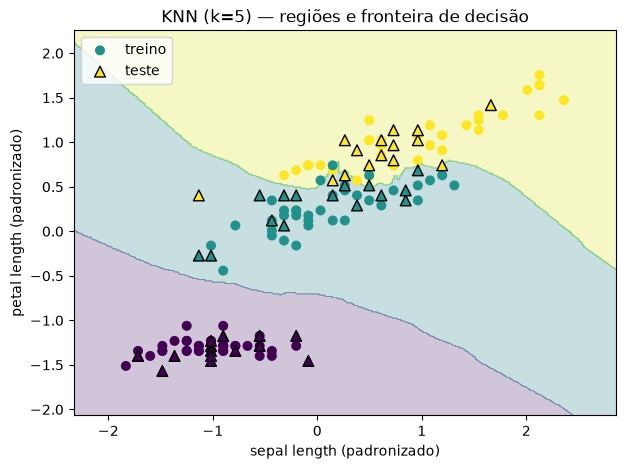

Acurácia no teste: 0.8888888888888888


In [5]:
# Exemplo com scikit-learn: Iris usando apenas 2 features.
X_iris_2d = iris.data[:, [0, 2]]  # sepal length, petal length
y_iris = iris.target

Xi_train_2d, Xi_test_2d, yi_train_2d, yi_test_2d = train_test_split(
    X_iris_2d, y_iris,
    test_size=0.3,
    random_state=42,
    stratify=y_iris
)

scaler_iris = StandardScaler()
Xi_train_2d_s = scaler_iris.fit_transform(Xi_train_2d)
Xi_test_2d_s = scaler_iris.transform(Xi_test_2d)

knn_sklearn_5 = KNeighborsClassifier(n_neighbors=5)
knn_sklearn_5.fit(Xi_train_2d_s, yi_train_2d)

plot_fronteira_decisao(
    knn_sklearn_5,
    Xi_train_2d_s, yi_train_2d,
    Xi_test_2d_s, yi_test_2d,
    titulo="KNN (k=5) — regiões e fronteira de decisão",
    nomes_features=("sepal length (padronizado)", "petal length (padronizado)")
)
plt.show()

print("Acurácia no teste:",
      accuracy_score(yi_test_2d, knn_sklearn_5.predict(Xi_test_2d_s)))


### Como $k$ muda a fronteira?

Agora podemos **ver** o trade-off viés-variância.

- com $k=1$, cada exemplo individual tem muita influência;
- ao aumentar $k$, a votação considera uma vizinhança maior e tende a suavizar pequenas irregularidades;
- com $k$ grande demais, regiões locais importantes podem desaparecer.

O código abaixo mantém exatamente os mesmos dados e muda apenas $k$.


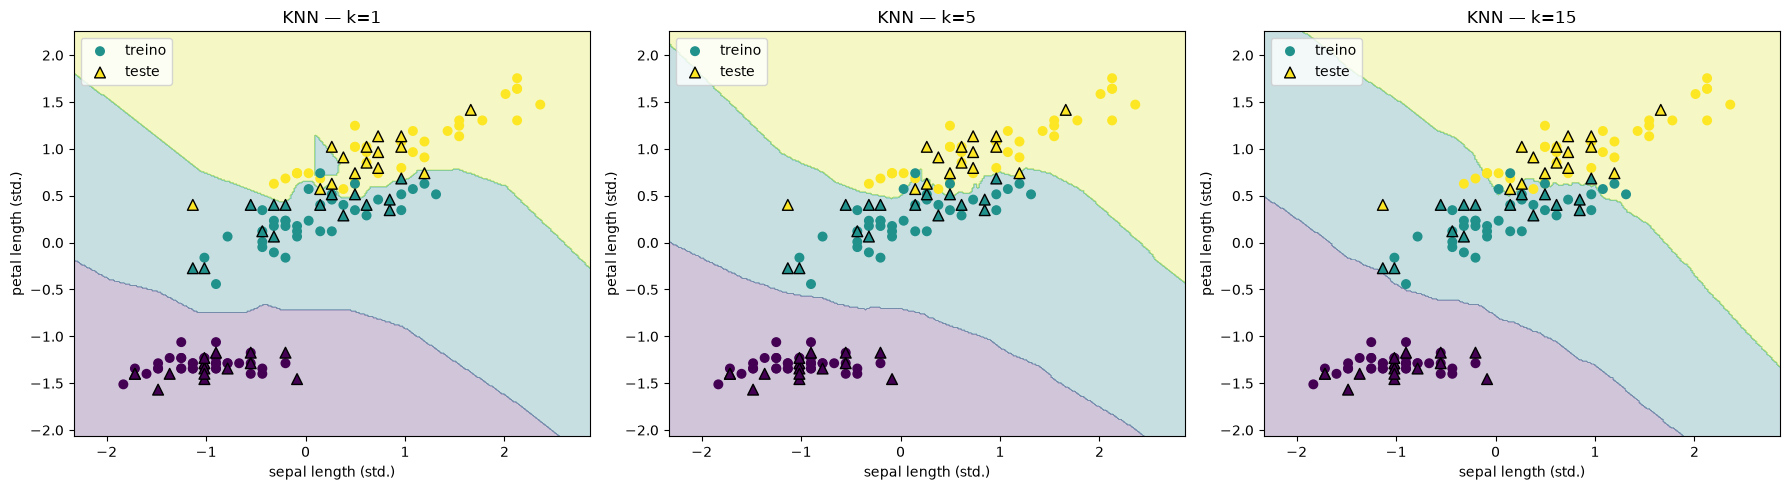

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for k, ax in zip([1, 5, 15], axes):
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(Xi_train_2d_s, yi_train_2d)

    plot_fronteira_decisao(
        modelo,
        Xi_train_2d_s, yi_train_2d,
        Xi_test_2d_s, yi_test_2d,
        titulo=f"KNN — k={k}",
        nomes_features=("sepal length (std.)", "petal length (std.)"),
        ax=ax
    )

plt.tight_layout()
plt.show()


### Exercício 2 — Interpretando a fronteira de decisão

Observe os gráficos para $k=1$, $k=5$ e $k=15$.

**Pergunta:** quais mudanças você observa no formato das regiões de decisão à medida que $k$ cresce? Relacione sua resposta com **overfitting**, **underfitting**, **viés** e **variância**.

---

## ✅ RESPOSTA — Exercício 2

**O que muda no gráfico.** Com $k=1$ as regiões têm bordas recortadas e aparecem **ilhas** de uma classe cercadas por outra — pequenos enclaves ao redor de pontos isolados, inclusive na zona onde *versicolor* e *virginica* se misturam. Com $k=5$ essas ilhas desaparecem quase todas e a fronteira fica contínua. Com $k=15$ a fronteira é quase uma reta suave, e parte dos pontos de treino da região de mistura passa a cair **do lado errado** da sua própria fronteira.

**Por que isso acontece — o mecanismo, não o efeito.** A predição em um ponto é a média (votação) dos rótulos dos $k$ vizinhos. Isso é um **estimador local da classe**, e aumentar $k$ é aumentar o tamanho da amostra usada em cada estimativa:

- com $k=1$, cada predição depende de **um único rótulo**. Um ponto rotulado por ruído (ou um exemplo legitimamente atípico) dita a classe de toda a sua vizinhança, e é exatamente isso que produz as ilhas. A fronteira é o **diagrama de Voronoi** dos pontos de treino: ela é obrigada a passar entre cada par de vizinhos de classes diferentes, por isso o recorte;
- cada vizinho extra adiciona um voto e **dilui** o peso de qualquer rótulo individual. A variância da estimativa local cai aproximadamente com $1/k$, e a fronteira perde os detalhes que vinham de pontos únicos;
- em troca, a vizinhança passa a abranger uma área maior do plano, onde a probabilidade real de cada classe já **não é constante**. A média mistura regiões de classes diferentes, e aparece um erro sistemático: isso é **viés**.

**Mapeando nos quatro termos.**

| | $k$ pequeno ($k=1$) | $k$ grande ($k=15$) |
|---|---|---|
| variância | **alta** — trocar um ponto de treino muda a fronteira | **baixa** — a fronteira quase não reage a um ponto |
| viés | **baixo** — a fronteira acompanha qualquer detalhe local | **alto** — detalhes locais são apagados |
| sintoma | **overfitting**: acurácia de treino 100% (cada ponto é seu próprio vizinho mais próximo), acurácia de teste menor | **underfitting**: erra também no treino, porque a fronteira é rígida demais |

**A evidência numérica está no Exercício 3:** no Wine, $k=1$ dá **100,00%** de acurácia no treino e 96,30% no teste — a assinatura do overfitting, com o modelo decorando os próprios dados. Conforme $k$ cresce, a acurácia de treino cai monotonicamente (até 96,77% em $k=25$) enquanto a de teste **sobe** e depois estabiliza: o ganho em variância supera a perda em viés até certo ponto, e é esse ponto que a validação procura.

Dois detalhes que o gráfico esconde e vale registrar: (i) $k$ é um hiperparâmetro **inverso** da complexidade — $k$ grande significa modelo mais simples, ao contrário da intuição de "número maior, modelo maior"; (ii) no limite $k=n$ o KNN prevê sempre a classe majoritária, ou seja, degenera no `DummyClassifier`.

---

### Exercício 3 — Escolhendo $k$ por validação

(a) Treine um `KNeighborsClassifier` (dados normalizados, dataset Wine) para $k \in \{1, 3, 5, ..., 25\}$ e plote **acurácia de treino vs. acurácia de teste** em função de $k$.

(b) Responda: qual $k$ você escolheria? Identifique no gráfico as regiões de overfitting e underfitting.

(c) Repita usando `GridSearchCV` (5-fold) e compare com sua escolha manual.

In [ ]:
# ✅ RESPOSTA — Exercício 3 (a): curva de acurácia treino/teste vs k
ks = range(1, 26, 2)

# O scaler `sc` da célula anterior já foi ajustado SOMENTE em Xw_train.
Xw_train_s = sc.transform(Xw_train)
Xw_test_s = sc.transform(Xw_test)

acc_treino, acc_teste = [], []
for k in ks:
    modelo_k = KNeighborsClassifier(n_neighbors=k).fit(Xw_train_s, yw_train)
    acc_treino.append(accuracy_score(yw_train, modelo_k.predict(Xw_train_s)))
    acc_teste.append(accuracy_score(yw_test, modelo_k.predict(Xw_test_s)))

print(f"{'k':>3} | {'treino':>7} | {'teste':>7}")
print("-" * 23)
for k, a_tr, a_te in zip(ks, acc_treino, acc_teste):
    print(f"{k:>3} | {a_tr:>7.4f} | {a_te:>7.4f}")

plt.figure(figsize=(7.5, 4.2))
plt.plot(list(ks), acc_treino, marker="o", label="treino")
plt.plot(list(ks), acc_teste, marker="s", label="teste")
plt.axvspan(0.5, 3.5, alpha=0.12, color="red")
plt.text(1.6, 0.955, "overfitting\n(variância alta)", ha="center", fontsize=8)
plt.xlabel("k (nº de vizinhos)")
plt.ylabel("acurácia")
plt.title("Wine padronizado — acurácia vs k")
plt.xticks(list(ks))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"\nk=1: treino = {acc_treino[0]:.4f}  <- cada ponto é seu próprio vizinho (overfitting)")
print(f"maior acurácia de TESTE: k = {list(ks)[int(np.argmax(acc_teste))]} "
      f"({max(acc_teste):.4f}) — mas ver o item (c): escolher k pelo teste é vazamento")

In [ ]:
# ✅ RESPOSTA — Exercício 3 (c): GridSearchCV
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# O Pipeline garante que o StandardScaler seja reajustado DENTRO de cada dobra,
# sem ver a parte usada para validar.
pipe_knn = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier())])

grid_knn = GridSearchCV(pipe_knn, {"knn__n_neighbors": list(ks)},
                        cv=5, scoring="accuracy")
grid_knn.fit(Xw_train, yw_train)

k_cv = grid_knn.best_params_["knn__n_neighbors"]
print(f"melhor k por validação cruzada 5-fold: {k_cv}  (acurácia média = {grid_knn.best_score_:.4f})")
print(f"acurácia no teste com esse k:          {accuracy_score(yw_test, grid_knn.predict(Xw_test)):.4f}")

tabela_cv = pd.DataFrame({
    "k": list(ks),
    "cv_media": grid_knn.cv_results_["mean_test_score"],
    "cv_desvio": grid_knn.cv_results_["std_test_score"],
    "acc_teste": acc_teste,
})
print()
print(tabela_cv.round(4).to_string(index=False))

print(f"\nFaixa coberta por 1 desvio-padrão do melhor k: "
      f"[{grid_knn.best_score_ - tabela_cv['cv_desvio'].iloc[int(np.argmax(tabela_cv['cv_media']))]:.4f}, "
      f"{grid_knn.best_score_ + tabela_cv['cv_desvio'].iloc[int(np.argmax(tabela_cv['cv_media']))]:.4f}]")
print("Quase todos os k caem dentro dessa faixa: a diferença entre eles não é significativa.")

**Sua resposta (Exercício 3b):**

---

## ✅ RESPOSTA — Exercício 3 (b) e (c)

**Qual $k$ eu escolheria: $k = 13$** — o valor apontado pela validação cruzada 5-fold, **não** o que maximiza a acurácia de teste.

**O que a curva mostra.**

| região | $k$ | treino | teste | leitura |
|:--|:--|--:|--:|:--|
| **overfitting** | 1 | **1,0000** | 0,9630 | o modelo decora: todo ponto é vizinho de si mesmo, erro de treino zero por construção |
| transição | 3–11 | 0,9839 → 0,9758 | 0,9444 → 0,9630 | a diluição dos votos reduz variância e o teste melhora |
| **boa região** | 13–21 | 0,9758 → 0,9677 | 0,9815 → 1,0000 | treino e teste próximos: variância controlada, viés ainda baixo |
| rumo ao **underfitting** | 23–25 | 0,9677 | 0,9815 | treino já caindo; com $k$ muito maior que isso a fronteira viraria quase linear |

Note que o Wine é um problema **fácil e pequeno** (178 amostras, 3 classes bem separadas depois da padronização): a curva de teste nunca desaba, então o underfitting não aparece em cheio nesta faixa de $k$. Ele apareceria com $k$ da ordem de algumas dezenas, até o limite $k = n_{\text{treino}} = 124$, em que o KNN prevê sempre a classe majoritária e a acurácia cairia para ≈ 0,40.

**Por que não escolher $k = 21$, que deu 100% no teste.** Porque esse 1,0000 foi **selecionado olhando o teste**. Escolher o hiperparâmetro pela nota do teste e depois reportar essa mesma nota é vazamento: o número deixa de ser uma estimativa honesta de desempenho futuro e passa a ser o máximo de 13 tentativas. O conjunto de teste tem apenas **54 amostras** — um acerto a mais ou a menos vale 1,85 ponto percentual, então a diferença entre 0,9630 e 1,0000 são **dois** exemplos.

**O que a validação cruzada diz (item c).** O `GridSearchCV` 5-fold, aplicado **só ao treino** e com o `StandardScaler` dentro do `Pipeline` (reajustado em cada dobra, sem ver a parte de validação), escolhe $k = 13$ com acurácia média de **0,9673**. Aplicado ao teste, esse $k$ dá **0,9815**.

A comparação entre os dois critérios é o ponto do exercício:

- minha escolha manual pela curva de teste seria $k = 21$; a escolha por validação cruzada é $k = 13$. **São diferentes**, e a segunda é a defensável, porque usou apenas dados de treino;
- o desvio-padrão entre as 5 dobras no melhor $k$ é **0,0310** — ou seja, a faixa de ±1 desvio é $[0{,}936;\ 0{,}998]$ e **engloba praticamente todos os $k$ testados** (de 0,9433 a 0,9673). A conclusão honesta é que, neste dataset, **a escolha de $k$ entre 5 e 25 é estatisticamente indistinguível**;
- havendo empate prático, aplico o critério secundário: prefiro o $k$ do meio da faixa estável (13), porque fica longe do regime de alta variância ($k$ pequeno) e longe do viés crescente ($k$ grande), e porque um $k$ maior é mais robusto a um rótulo errado no treino.

**Detalhe de método que vale registrar:** a acurácia de treino do KNN com $k=1$ é 1,0000 por uma razão estrutural, não por mérito — o ponto consultado está no próprio conjunto memorizado e tem distância zero de si mesmo. Por isso a acurácia de treino do KNN é **inútil como estimativa de generalização**, e a curva só informa quando lida junto com a de teste (ou, melhor, com a de validação cruzada).

---

## 1.7 KNN para regressão

Na regressão, a ideia de vizinhança é a mesma. O que muda é a forma de produzir a saída:

$$
\hat y(x)=\frac{1}{k}\sum_{i\in N_k(x)} y_i.
$$

Ou seja, o valor previsto é, na versão mais simples, a **média dos alvos dos $k$ vizinhos mais próximos**.

### Exemplo guiado — `KNeighborsRegressor`

Vamos variar $k$ no dataset Diabetes. O código já está implementado porque o objetivo aqui é interpretar duas métricas:

- **RMSE**: erro na mesma unidade do alvo; menor é melhor;
- **$R^2$**: proporção da variabilidade explicada pelo modelo; maior é melhor.

Observe que aumentar $k$ não garante melhora monotônica: novamente existe um compromisso entre sensibilidade local e suavização.


  k |      RMSE |      R²
---------------------------
  1 |    77.244 |  -0.105
  3 |    60.253 |   0.327
  5 |    57.252 |   0.393
 10 |    56.287 |   0.413
 20 |    53.978 |   0.460


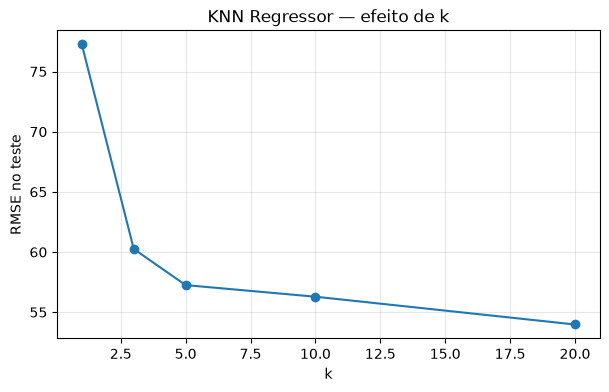

In [7]:
from sklearn.neighbors import KNeighborsRegressor

Xd_knn_train, Xd_knn_test, yd_knn_train, yd_knn_test = train_test_split(
    diabetes.data, diabetes.target,
    test_size=0.3,
    random_state=42
)

scaler_reg = StandardScaler()
Xd_knn_train_s = scaler_reg.fit_transform(Xd_knn_train)
Xd_knn_test_s = scaler_reg.transform(Xd_knn_test)

ks_reg = [1, 3, 5, 10, 20]
resultados_reg = []

for k in ks_reg:
    reg_knn = KNeighborsRegressor(n_neighbors=k)
    reg_knn.fit(Xd_knn_train_s, yd_knn_train)

    pred = reg_knn.predict(Xd_knn_test_s)
    rmse = np.sqrt(mean_squared_error(yd_knn_test, pred))
    r2 = r2_score(yd_knn_test, pred)

    resultados_reg.append((k, rmse, r2))

print(f"{'k':>3} | {'RMSE':>9} | {'R²':>7}")
print("-" * 27)
for k, rmse, r2 in resultados_reg:
    print(f"{k:>3} | {rmse:>9.3f} | {r2:>7.3f}")

plt.figure(figsize=(7, 4))
plt.plot(
    [r[0] for r in resultados_reg],
    [r[1] for r in resultados_reg],
    marker="o"
)
plt.xlabel("k")
plt.ylabel("RMSE no teste")
plt.title("KNN Regressor — efeito de k")
plt.grid(alpha=0.3)
plt.show()


### Exercício 4 — Interpretação e implementação opcional

**(a)** Com base na tabela e no gráfico acima, qual dos valores de $k$ testados apresentou o menor RMSE? O mesmo valor também apresentou o maior $R^2$? Explique por que é melhor comparar modelos no mesmo conjunto de teste/validação.

**(b) Bônus:** implemente um `KNNRegressor` do zero reutilizando `euclidean_distances`. A estrutura é praticamente a mesma do classificador, mas a votação é substituída pela média dos valores-alvo dos vizinhos.


In [ ]:
# ✅ RESPOSTA — Exercício 4 (b, bônus): KNNRegressor do zero
class KNNRegressor:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        # mesma ideia do classificador: "treinar" é memorizar
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=float)
        return self

    def _predict_one(self, x):
        idx_vizinhos = np.argsort(euclidean_distances(self.X_train, x))[:self.k]
        # única diferença em relação ao classificador: média em vez de votação
        return self.y_train[idx_vizinhos].mean()

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x) for x in X])


# Conferência contra o scikit-learn no mesmo split do exemplo guiado
print(f"{'k':>3} | {'RMSE (meu)':>11} | {'RMSE (sklearn)':>15} | iguais?")
print("-" * 48)
for k in [1, 3, 5, 10, 20]:
    meu = KNNRegressor(k=k).fit(Xd_knn_train_s, yd_knn_train).predict(Xd_knn_test_s)
    ref = KNeighborsRegressor(n_neighbors=k).fit(Xd_knn_train_s, yd_knn_train).predict(Xd_knn_test_s)
    rmse_meu = np.sqrt(mean_squared_error(yd_knn_test, meu))
    rmse_ref = np.sqrt(mean_squared_error(yd_knn_test, ref))
    print(f"{k:>3} | {rmse_meu:>11.4f} | {rmse_ref:>15.4f} | {np.allclose(meu, ref)}")

# Verificação da identidade R² = 1 - MSE/Var(y) usada na resposta do item (a)
pred20 = KNNRegressor(k=20).fit(Xd_knn_train_s, yd_knn_train).predict(Xd_knn_test_s)
mse20 = mean_squared_error(yd_knn_test, pred20)
print(f"\nR² (sklearn)          = {r2_score(yd_knn_test, pred20):.6f}")
print(f"1 - MSE/Var(y_teste)  = {1 - mse20 / np.var(yd_knn_test):.6f}  <- mesma coisa")

---

## ✅ RESPOSTA — Exercício 4 (a)

**Menor RMSE: $k = 20$**, com RMSE $= 53{,}978$. E **sim**, o mesmo $k$ também tem o maior $R^2$ ($0{,}4603$).

| $k$ | RMSE | $R^2$ |
|--:|--:|--:|
| 1 | 77,244 | **−0,1053** |
| 3 | 60,253 | 0,3275 |
| 5 | 57,252 | 0,3928 |
| 10 | 56,287 | 0,4131 |
| **20** | **53,978** | **0,4603** |

**A coincidência não é sorte — é identidade algébrica.** No **mesmo** conjunto de teste,

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2} = 1 - \frac{\mathrm{MSE}}{\mathrm{Var}(y)},$$

e $\mathrm{Var}(y)$ é uma propriedade dos **dados**, não do modelo: é a mesma constante para todos os $k$. Logo $R^2$ é uma função estritamente decrescente do MSE, e ordenar por RMSE crescente é ordenar por $R^2$ decrescente. A célula de código acima confere a identidade numericamente ($0{,}460268$ pelos dois caminhos). Ou seja: nesse cenário, reportar as duas métricas não acrescenta informação sobre o *ranking* — acrescenta interpretabilidade (RMSE em unidades do alvo, $R^2$ adimensional).

**Por que comparar modelos sempre no mesmo conjunto.** Exatamente porque a identidade acima depende de um $\mathrm{Var}(y)$ comum. Se eu medir o modelo A em uma partição e o modelo B em outra, estou comparando frações com **denominadores diferentes**: uma partição com alvos mais dispersos infla o $R^2$ de qualquer modelo, e uma partição "fácil" reduz o RMSE sem nenhum mérito do modelo. A comparação só isola o efeito do modelo quando os dados de avaliação são idênticos — mesmas amostras, mesma ordem, mesmo pré-processamento. É o mesmo princípio que torna o *pareamento* a forma correta de comparar dois modelos.

**Observação sobre $k = 1$ com $R^2$ negativo.** $R^2 = -0{,}1053$ significa que o modelo é **pior que prever sempre a média** do alvo. Faz sentido: com um único vizinho, a predição carrega todo o ruído daquele paciente, e o Diabetes é um problema de sinal fraco (apenas 10 features, forte variabilidade individual). É mais um registro de que $k$ pequeno em KNN é variância pura — e aqui a variância custa mais do que o viés da média global.

---

# Parte 2 — Árvores de Decisão

## 2.1 Intuição: uma sequência de perguntas

Uma árvore de decisão aprende regras do tipo

$$
x_j \leq t\;?
$$

Cada pergunta divide os exemplos em dois grupos. Repetindo esse processo, o espaço de entrada é particionado em regiões progressivamente mais homogêneas.

Uma árvore é um modelo **não paramétrico**: não existe um número fixo de coeficientes definido antes do treinamento. A complexidade da estrutura pode crescer com os dados. Ao mesmo tempo, seu treinamento é **eager**: a árvore é construída no `fit`; depois disso, a predição percorre apenas a estrutura aprendida.

Características importantes:

- **não exige padronização** para os splits usuais por limiar;
- produz regras explicitáveis;
- consegue modelar relações não lineares;
- pode sofrer *overfitting* se crescer sem restrições.

---

## 2.2 Como a árvore escolhe uma pergunta?

Em classificação, queremos que cada divisão produza filhos mais **puros**.

### Impureza de Gini

$$
G = 1-\sum_{c=1}^{C}p_c^2.
$$

No caso binário:

- 100% / 0%  $\rightarrow G=0$: nó puro;
- 90% / 10%  $\rightarrow G=0.18$;
- 50% / 50%  $\rightarrow G=0.5$: máxima mistura.

### Entropia

$$
H=-\sum_{c=1}^{C}p_c\log_2(p_c).
$$

Assim como o Gini, a entropia é zero quando o nó contém apenas uma classe.

### Ganho de informação / redução de impureza

Considere um nó $N$ dividido em $N_{\text{esq}}$ e $N_{\text{dir}}$. A qualidade da divisão pode ser medida por:

$$
\text{ganho}
=
I(N)
-
\frac{|N_{\text{esq}}|}{|N|}I(N_{\text{esq}})
-
\frac{|N_{\text{dir}}|}{|N|}I(N_{\text{dir}}),
$$

onde $I$ é a medida de impureza.

A ideia é simples: **um bom split reduz bastante a impureza ponderada dos filhos**.

O algoritmo é guloso: em cada nó, escolhe a melhor decisão disponível naquele momento. Isso não garante a árvore globalmente ótima, mas torna o treinamento viável.

---

## 2.3 Construção recursiva e controle de complexidade

A construção pode ser entendida recursivamente:

1. se o nó já está suficientemente puro ou algum critério de parada foi atingido, crie uma folha;
2. caso contrário, encontre o melhor par `(feature, limiar)`;
3. divida os dados;
4. repita o processo em cada filho.

Sem controle, a árvore pode continuar criando folhas até memorizar peculiaridades do conjunto de treino.

Hiperparâmetros importantes:

- `max_depth`: profundidade máxima;
- `min_samples_split`: mínimo de amostras para tentar dividir um nó;
- `min_samples_leaf`: mínimo de amostras em uma folha;
- `ccp_alpha`: poda por *cost-complexity*.


## 2.4 Implementação do zero com NumPy

### Exercício 5 — Impurezas

Implemente as funções de impureza. Depois, verifique com os asserts.

In [ ]:
def gini(y):
    """Impureza de Gini de um vetor de rótulos y."""
    # ✅ RESPOSTA — Exercício 5
    _, contagens = np.unique(y, return_counts=True)
    p = contagens / contagens.sum()
    return 1.0 - np.sum(p ** 2)

def entropia(y):
    """Entropia (base 2) de um vetor de rótulos y."""
    # ✅ RESPOSTA — Exercício 5
    _, contagens = np.unique(y, return_counts=True)
    p = contagens / contagens.sum()
    p = p[p > 0]                      # 0·log0 ≡ 0: descartamos as classes ausentes
    return -np.sum(p * np.log2(p))

# Testes
try:
    assert abs(gini(np.array([0,0,0,0])) - 0.0) < 1e-9          # puro
    assert abs(gini(np.array([0,0,1,1])) - 0.5) < 1e-9          # máximo (binário)
    assert abs(entropia(np.array([0,0,1,1])) - 1.0) < 1e-9
    assert abs(entropia(np.array([1,1,1,1])) - 0.0) < 1e-9
    print("OK! Impurezas corretas.")
except NotImplementedError:
    print("Pendente: implemente gini e entropia")

# Conferências extras contra os valores citados na Seção 2.2 do notebook
print(f"90%/10%  -> Gini = {gini(np.array([0]*9 + [1])):.4f}  (texto: 0,18)")
print(f"50%/50%  -> Gini = {gini(np.array([0,1])):.4f}  (máximo binário)")
print(f"3 classes iguais -> Gini = {gini(np.array([0,1,2])):.4f} = 1 - 3·(1/3)² = 2/3")
print(f"3 classes iguais -> Entropia = {entropia(np.array([0,1,2])):.4f} = log2(3)")
print("\nNota: `np.unique` só devolve as classes PRESENTES, então as ausentes já ficam de")
print("fora da soma. O filtro p > 0 protege contra pesos nulos vindos de outra origem.")

### Árvore de decisão do zero — esqueleto guiado

Abaixo, parte da estrutura está pronta. Você implementará a **busca pelo melhor split** (`_best_split`), que é o coração do algoritmo.

In [ ]:
class No:
    """Nó da árvore: ou é folha (tem 'valor') ou é interno (tem feature, limiar e filhos)."""
    def __init__(self, feature=None, limiar=None, esq=None, dir=None, valor=None):
        self.feature = feature
        self.limiar = limiar
        self.esq = esq
        self.dir = dir
        self.valor = valor  # classe majoritária, se folha

    def eh_folha(self):
        return self.valor is not None


class ArvoreDecisao:
    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y)
        self.raiz = self._construir(self.X, self.y, profundidade=0)
        return self

    def _classe_majoritaria(self, y):
        return Counter(y).most_common(1)[0][0]

    def _construir(self, X, y, profundidade):
        n = len(y)
        # Critérios de parada -> folha
        if (profundidade >= self.max_depth
                or n < self.min_samples_split
                or len(np.unique(y)) == 1):
            return No(valor=self._classe_majoritaria(y))

        feature, limiar = self._best_split(X, y)
        if feature is None:  # nenhum split melhora
            return No(valor=self._classe_majoritaria(y))

        mask = X[:, feature] <= limiar
        esq = self._construir(X[mask], y[mask], profundidade + 1)
        dir = self._construir(X[~mask], y[~mask], profundidade + 1)
        return No(feature=feature, limiar=limiar, esq=esq, dir=dir)

    def _best_split(self, X, y):
        """Retorna (feature, limiar) do split com maior ganho de informação (Gini),
        ou (None, None) se nenhum split tiver ganho positivo."""
        n_amostras, n_features = X.shape
        impureza_atual = gini(y)
        melhor_ganho, melhor_feature, melhor_limiar = 0.0, None, None

        for j in range(n_features):
            limiares = np.unique(X[:, j])
            for t in limiares:
                mask = X[:, j] <= t
                if mask.sum() == 0 or (~mask).sum() == 0:
                    continue
                # ✅ RESPOSTA — Exercício 5 (coração do algoritmo)
                p_esq = mask.sum() / n_amostras
                p_dir = 1.0 - p_esq                      # = (~mask).sum() / n_amostras
                impureza_filhos = p_esq * gini(y[mask]) + p_dir * gini(y[~mask])
                ganho = impureza_atual - impureza_filhos
                if ganho > melhor_ganho:
                    melhor_ganho = ganho
                    melhor_feature = j
                    melhor_limiar = t

        return melhor_feature, melhor_limiar

    def _predict_one(self, x, no):
        while not no.eh_folha():
            no = no.esq if x[no.feature] <= no.limiar else no.dir
        return no.valor

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x, self.raiz) for x in X])

# Três observações sobre a implementação:
#   1. a impureza dos filhos é PONDERADA pelo tamanho de cada lado — sem isso, um split
#      que isola uma única amostra (filho puro, Gini 0) pareceria ótimo;
#   2. `melhor_ganho` começa em 0,0, então splits com ganho nulo são rejeitados e o nó
#      vira folha. É o que faz `_best_split` devolver (None, None);
#   3. o laço testa cada valor observado como limiar — O(n_features · n_valores · n).
#      O scikit-learn usa o PONTO MÉDIO entre valores consecutivos e ordena uma vez só,
#      o que explica pequenas diferenças de fronteira entre as duas árvores.

### Testando sua árvore

In [ ]:
# Iris com as 4 features, sem normalização (árvores não precisam!)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=42, stratify=iris.target)

try:
    minha_arvore = ArvoreDecisao(max_depth=4)
    minha_arvore.fit(Xi_train, yi_train)
    pred = minha_arvore.predict(Xi_test)
    print("Acurácia (sua árvore):", accuracy_score(yi_test, pred))
except Exception as e:
    print("Complete o TODO em _best_split. Erro:", e)

# ✅ Conferência extra: comparação com o scikit-learn e leitura da raiz aprendida
from sklearn.tree import DecisionTreeClassifier as _DTC
ref = _DTC(max_depth=4, random_state=42).fit(Xi_train, yi_train)
print("Acurácia (scikit-learn, max_depth=4):", accuracy_score(yi_test, ref.predict(Xi_test)))

raiz = minha_arvore.raiz
print(f"\nPrimeira pergunta da sua árvore: {iris.feature_names[raiz.feature]} <= {raiz.limiar}")
print(f"Ganho de Gini na raiz: {gini(yi_train):.4f} (impureza inicial, 3 classes equilibradas)")
print("A raiz escolhe petal length — a feature que separa setosa das outras duas sem erro.")

## 2.5 Árvores com scikit-learn

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Sem limite de profundidade vs. limitada
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.3, random_state=42, stratify=cancer.target)

for depth in [None, 3]:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(Xc_train, yc_train)
    acc_tr = accuracy_score(yc_train, clf.predict(Xc_train))
    acc_te = accuracy_score(yc_test, clf.predict(Xc_test))
    print(f"max_depth={depth}: treino={acc_tr:.3f} | teste={acc_te:.3f}")

max_depth=None: treino=1.000 | teste=0.918
max_depth=3: treino=0.980 | teste=0.924


### Lendo uma árvore treinada

No gráfico abaixo:

- cada caixa representa um nó;
- a primeira linha mostra a regra do split;
- `gini` indica a impureza;
- `samples` mostra quantas amostras chegaram ao nó;
- `value` mostra a distribuição das classes;
- `class` é a classe prevista naquele nó.

Para classificar uma nova amostra, começamos na raiz e seguimos para a esquerda ou para a direita de acordo com cada condição até alcançar uma folha.


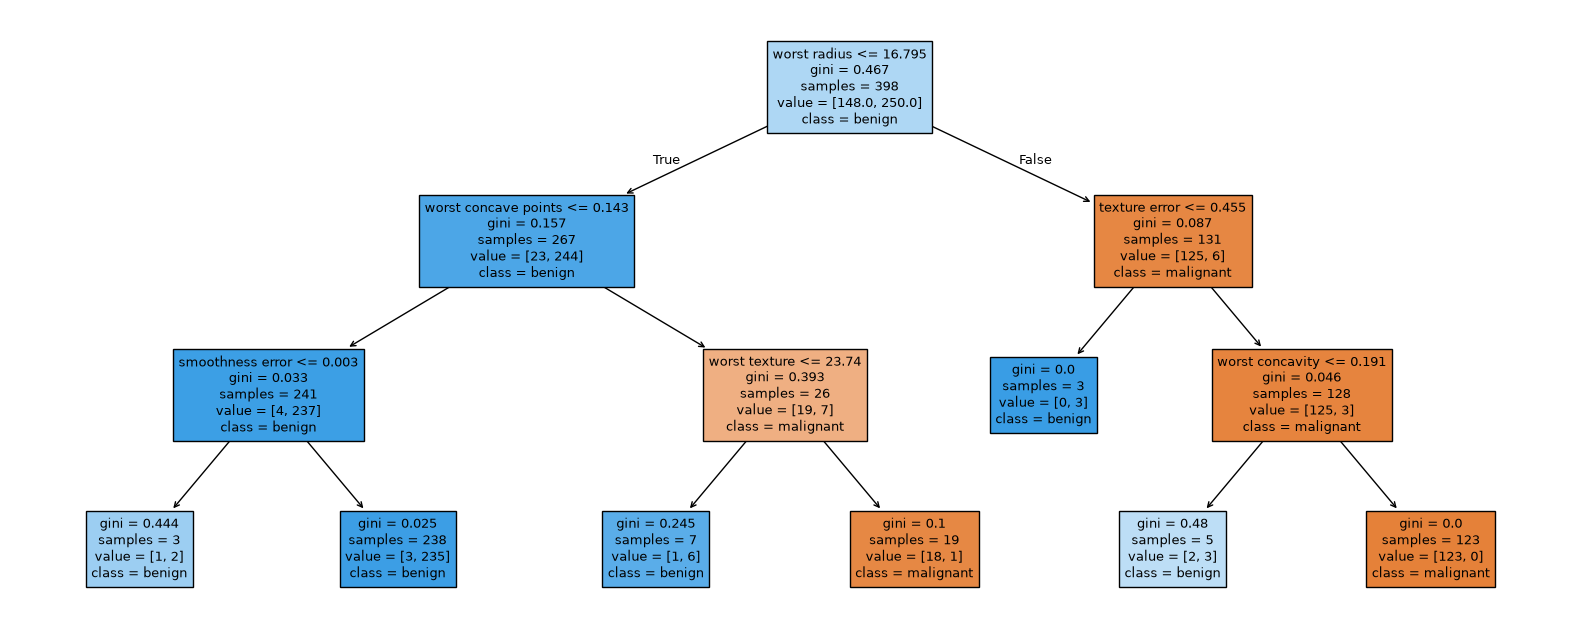

In [9]:
# Visualizando a árvore (interpretabilidade!)
clf_small = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_small.fit(Xc_train, yc_train)

plt.figure(figsize=(20, 8))
plot_tree(clf_small, feature_names=cancer.feature_names,
          class_names=cancer.target_names, filled=True, fontsize=9)
plt.show()

### Exercício 6 — Avaliação completa no Breast Cancer

Usando um `DecisionTreeClassifier` bem ajustado no dataset Breast Cancer:

(a) Use `GridSearchCV` (5-fold) sobre `max_depth` (2 a 10) e `min_samples_leaf` (1, 2, 5, 10) para encontrar a melhor combinação.

(b) Para o melhor modelo no conjunto de teste, reporte: **acurácia, precisão, recall, F1 e ROC/AUC**, e plote a **matriz de confusão**. (Revisite o notebook de classificação se precisar.)

(c) Interprete: neste problema (diagnóstico de câncer), qual erro é mais grave — falso positivo ou falso negativo? Qual métrica você priorizaria e por quê?

In [ ]:
# ✅ RESPOSTA — Exercício 6 (a): GridSearchCV
from sklearn.model_selection import GridSearchCV

grade = {"max_depth": list(range(2, 11)),
         "min_samples_leaf": [1, 2, 5, 10]}

busca_arvore = GridSearchCV(DecisionTreeClassifier(random_state=42),
                            grade, cv=5, scoring="accuracy")
busca_arvore.fit(Xc_train, yc_train)

melhor_arvore = busca_arvore.best_estimator_
print("melhores hiperparâmetros:", busca_arvore.best_params_)
print(f"acurácia média na validação cruzada: {busca_arvore.best_score_:.4f}")
print(f"combinações avaliadas: {len(busca_arvore.cv_results_['params'])}  (9 profundidades × 4 min_samples_leaf)")

# A grade inteira, para ver se a escolha é estável ou um pico de ruído
import pandas as pd
res = pd.DataFrame(busca_arvore.cv_results_)[
    ["param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]]
print("\n5 melhores combinações:")
print(res.sort_values("mean_test_score", ascending=False).head().round(4).to_string(index=False))
print(f"\nMelhor média ({busca_arvore.best_score_:.4f}) ± 1 desvio = "
      f"[{busca_arvore.best_score_ - res['std_test_score'].max():.4f}, "
      f"{busca_arvore.best_score_ + res['std_test_score'].max():.4f}]: "
      "boa parte da grade cai nessa faixa.")

In [ ]:
# ✅ RESPOSTA — Exercício 6 (b): métricas + matriz de confusão
yc_pred = melhor_arvore.predict(Xc_test)
yc_prob = melhor_arvore.predict_proba(Xc_test)[:, 1]

# ATENÇÃO À CONVENÇÃO: no load_breast_cancer, 0 = malignant e 1 = benign.
# A classe positiva padrão do sklearn é a 1 -> BENIGNO. Reportamos as duas leituras.
print("classes_:", melhor_arvore.classes_, "->", dict(enumerate(cancer.target_names)))
print(f"teste: {len(yc_test)} amostras | malignos (0) = {int((yc_test == 0).sum())} "
      f"| benignos (1) = {int((yc_test == 1).sum())}\n")

print("--- classe positiva = 1 (benigno), padrão do scikit-learn ---")
print(f"acurácia : {accuracy_score(yc_test, yc_pred):.4f}")
print(f"precisão : {precision_score(yc_test, yc_pred):.4f}")
print(f"recall   : {recall_score(yc_test, yc_pred):.4f}")
print(f"F1       : {f1_score(yc_test, yc_pred):.4f}")
print(f"ROC/AUC  : {roc_auc_score(yc_test, yc_prob):.4f}   (independe do limiar)")

print("\n--- classe positiva = 0 (MALIGNO), a leitura clinicamente relevante ---")
print(f"precisão : {precision_score(yc_test, yc_pred, pos_label=0):.4f}")
print(f"recall   : {recall_score(yc_test, yc_pred, pos_label=0):.4f}   <- fração de cânceres detectados")
print(f"F1       : {f1_score(yc_test, yc_pred, pos_label=0):.4f}")

cm = confusion_matrix(yc_test, yc_pred)
print("\nmatriz de confusão (linhas = real, colunas = previsto; rótulos [0=maligno, 1=benigno]):")
print(cm)
print(f"\n  malignos previstos como benignos (o erro grave): {cm[0, 1]}")
print(f"  benignos previstos como malignos (biópsia extra): {cm[1, 0]}")

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(
    yc_test, yc_pred, display_labels=cancer.target_names,
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Árvore ajustada — Breast Cancer (teste)")
ax.set_xlabel("classe prevista"); ax.set_ylabel("classe real")
ax.grid(False)
plt.tight_layout(); plt.show()

**Sua resposta (Exercício 6c):**

---

## ✅ RESPOSTA — Exercício 6 (b) e (c)

**Resultados (b).** `GridSearchCV` 5-fold escolheu `max_depth=3`, `min_samples_leaf=2` (acurácia média de validação **0,9449**, sobre 36 combinações). No conjunto de teste (171 amostras: 64 malignas, 107 benignas):

| métrica | positivo = 1 (benigno, padrão do sklearn) | positivo = 0 (**maligno**) |
|:--|--:|--:|
| acurácia | 0,9240 | 0,9240 |
| precisão | 0,9273 | 0,9180 |
| recall | 0,9533 | **0,8750** |
| F1 | 0,9401 | 0,8960 |
| ROC/AUC | 0,9187 | 0,9187 |

Matriz de confusão (linhas = real, colunas = previsto, rótulos [maligno, benigno]):

$$\begin{bmatrix} 56 & 8 \\ 5 & 102 \end{bmatrix}$$

**O primeiro achado é uma armadilha de convenção**, e ela muda a leitura inteira: no `load_breast_cancer`, **0 = maligno e 1 = benigno**. Como o scikit-learn usa a classe 1 como positiva por padrão, o `recall = 0,9533` que sai do código "puro" é o recall dos **benignos** — a fração de pacientes saudáveis corretamente liberados. O número clinicamente relevante é o outro: **recall da classe maligna = 0,8750**. Reportar 0,95 como "sensibilidade do detector de câncer" seria um erro grosseiro de 8 pontos percentuais no indicador que decide vidas.

**(c) Qual erro é mais grave: o falso negativo**, isto é, **um tumor maligno classificado como benigno**. A assimetria é enorme e não é opinável:

- **falso negativo (8 casos no teste):** a paciente é liberada sem tratamento. O câncer continua progredindo até o próximo exame — se houver. O custo é perda de estadiamento, tratamento mais agressivo depois e risco de morte. É **irreversível**;
- **falso positivo (5 casos no teste):** a paciente é encaminhada para biópsia ou exame complementar, que descarta a doença. O custo é ansiedade, um procedimento invasivo de baixo risco e algumas centenas de reais. É **recuperável no passo seguinte do fluxo**.

Em um sistema de triagem, o falso positivo é absorvido pela própria cadeia diagnóstica; o falso negativo **sai** da cadeia.

**Métrica que eu priorizaria: recall da classe maligna (sensibilidade), com precisão como restrição secundária.** Justificativa operacional, nessa ordem:

1. **recall da classe maligna** — mede exatamente o que não pode falhar. Meta: o mais perto de 1,0 possível. Os 0,8750 atuais significam **8 de 64 cânceres passando**, o que eu não aprovaria para triagem;
2. **precisão da classe maligna** (0,9180) como piso de viabilidade — se o alarme disparar em todo mundo, o recall vai a 1,0 e o exame perde utilidade, entupindo a fila de biópsias;
3. **$F_\beta$ com $\beta = 2$ ou 3** (favorecendo recall) se for preciso um único número para comparar modelos, em vez do F1, que pesa os dois erros igualmente — o que este problema contradiz;
4. **AUC (0,9187)** para avaliar a **ordenação** independentemente do limiar, útil justamente porque o próximo passo é mover o limiar.

**O que eu faria em seguida** (e é o elo com o Notebook 5): não trocaria o modelo, trocaria o **ponto de operação**. A árvore devolve `predict_proba`; baixar o limiar de 0,5 para, digamos, 0,3 na probabilidade de "benigno" converte falsos negativos em falsos positivos — exatamente a troca que este problema quer. Com $c_{FN} \gg c_{FP}$, o limiar ótimo de Elkan é $t^\star = c_{FP}/(c_{FP}+c_{FN})$, bem abaixo de 0,5. Também otimizaria a busca por `scoring="recall"` em vez de `"accuracy"`: a grade atual foi escolhida maximizando acurácia, que é a métrica que **menos** representa este problema.

---

### Exercício 7 — Importância das features e visualização

(a) Extraia `feature_importances_` do seu melhor modelo do Exercício 6 e plote um gráfico de barras horizontal com as 10 features mais importantes.

(b) Plote a árvore do melhor modelo com `plot_tree` (se for muito profunda, treine uma versão com `max_depth=3` só para visualização) e descreva, em texto, a regra de decisão do caminho da raiz até a folha mais à esquerda.

In [ ]:
# ✅ RESPOSTA — Exercício 7 (a): feature importances
import pandas as pd

importancias = pd.Series(melhor_arvore.feature_importances_,
                         index=cancer.feature_names).sort_values(ascending=False)

top10 = importancias.head(10)
print(top10.round(4).to_string())
print(f"\nfeatures com importância > 0: {(importancias > 0).sum()} de {len(importancias)}")
print(f"as 3 primeiras concentram {top10.head(3).sum():.1%} da importância total")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index[::-1], top10.values[::-1], color="#2a78d6")
ax.set_xlabel("importância (redução total de Gini, normalizada)")
ax.set_title("10 features mais importantes — árvore ajustada (Breast Cancer)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

print("Como ler: a importância de uma feature é a soma das reduções de impureza dos nós")
print("que a usam, ponderada pelas amostras que passam por eles. Uma feature com 0,0000")
print("não foi escolhida por NENHUM nó — não significa que seja irrelevante, apenas que")
print("outra feature correlacionada foi escolhida primeiro (e há muitas, aqui).")

In [ ]:
# ✅ RESPOSTA — Exercício 7 (b): visualização da árvore
from sklearn.tree import export_text

# A melhor árvore já tem max_depth=3, então ela mesma é visualizável.
print("melhor_arvore: max_depth =", melhor_arvore.get_depth(), "| folhas =", melhor_arvore.get_n_leaves())

plt.figure(figsize=(22, 9))
plot_tree(melhor_arvore, feature_names=cancer.feature_names,
          class_names=cancer.target_names, filled=True, fontsize=9, rounded=True)
plt.title("Árvore escolhida pelo GridSearchCV (max_depth=3, min_samples_leaf=2)")
plt.show()

# Versão em texto: mais fácil de citar na resposta escrita
print(export_text(melhor_arvore, feature_names=list(cancer.feature_names), decimals=3))

**Sua resposta (Exercício 7b — descreva a regra):**

---

## ✅ RESPOSTA — Exercício 7 (a) e (b)

**(a) Importâncias.** A árvore escolhida usa **apenas 6 das 30 features**:

| feature | importância |
|:--|--:|
| `worst radius` | **0,7671** |
| `worst concave points` | 0,1386 |
| `worst texture` | 0,0384 |
| `texture error` | 0,0324 |
| `worst concavity` | 0,0200 |
| `smoothness error` | 0,0035 |
| as outras 24 | 0,0000 |

Uma única feature, `worst radius`, responde por **77%** da redução total de impureza; as três primeiras somam **94,4%**. Duas leituras importantes:

- **importância 0,0000 não significa "irrelevante".** `mean radius`, por exemplo, tem importância zero — e é uma das features mais correlacionadas com o diagnóstico. Ela ficou de fora porque `worst radius` carrega quase a mesma informação e foi escolhida primeiro; depois disso não resta ganho de Gini para a outra capturar. Em dados com features muito correlacionadas (o Breast Cancer tem três blocos — `mean`, `error`, `worst` — da mesma medida), a importância de uma árvore única é **instável**: pequenas mudanças nos dados trocam qual das irmãs correlacionadas entra. Florestas aleatórias atenuam isso por amostrar features em cada nó;
- a concentração em poucas features é consequência direta de `max_depth=3`: com no máximo 7 nós internos, **não há como** usar mais do que 7 features.

**(b) A regra do caminho da raiz até a folha mais à esquerda.** Seguindo sempre o ramo "verdadeiro" (à esquerda, condição satisfeita):

```
worst radius <= 16.795
└── worst concave points <= 0.143
    └── smoothness error <= 0.003
        └── classe prevista: benigno
```

**Em português:** *se o maior raio medido no núcleo celular é de no máximo 16,8 (tumor pequeno), **e** o pior valor de "pontos concavos" é de no máximo 0,143 (contorno pouco irregular), **e** o erro de suavidade é de no máximo 0,003, então o tumor é classificado como **benigno**.*

A regra é clinicamente coerente, e é isso que torna a árvore defensável diante de um radiologista: tumores **pequenos** e de **contorno regular** são benignos; os dois eixos que a árvore usa primeiro — tamanho (`worst radius`) e irregularidade do contorno (`worst concave points`) — são exatamente os critérios morfológicos que a literatura associa a malignidade.

Vale notar o **detalhe que a visualização revela**: o terceiro teste (`smoothness error <= 0.003`) não muda a decisão — os **dois** filhos dessa pergunta preveem benigno. É um split que reduziu Gini o suficiente para ser aceito pelo critério guloso, mas que não altera a classe prevista. Isso é o argumento prático a favor da **poda**: `ccp_alpha` ou um `min_impurity_decrease` removeria esse nó sem nenhuma perda de acurácia, deixando a árvore mais curta e mais fácil de explicar.

---

## 2.6 Árvores para regressão

Uma árvore de regressão mantém a mesma estrutura de perguntas por limiar, mas não tenta separar classes.

Em cada folha, a predição é tipicamente a **média dos valores-alvo** das amostras que chegaram até ali. Por isso, a função aprendida por uma árvore de regressão tem aparência de **degraus**: cada região da feature recebe um valor constante.

Os splits são escolhidos para reduzir um critério de erro, como o erro quadrático.


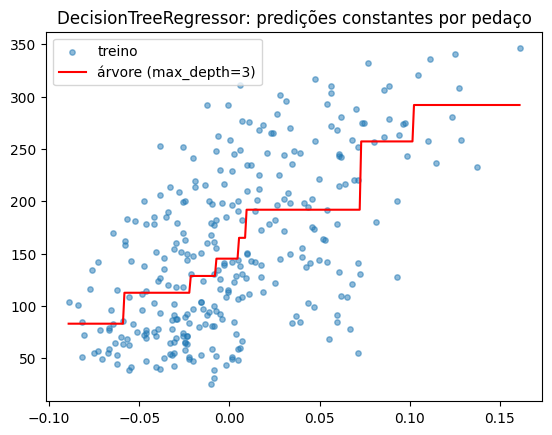

R² teste: 0.27808201405927124


In [22]:
from sklearn.tree import DecisionTreeRegressor

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    diabetes.data, diabetes.target, test_size=0.3, random_state=42)

# Efeito da profundidade: overfitting visual em 1 feature
feat = 2  # BMI
reg = DecisionTreeRegressor(max_depth=3, random_state=42)
reg.fit(Xd_train[:, [feat]], yd_train)

xg = np.linspace(Xd_train[:, feat].min(), Xd_train[:, feat].max(), 300).reshape(-1, 1)
plt.scatter(Xd_train[:, feat], yd_train, s=15, alpha=0.5, label="treino")
plt.plot(xg, reg.predict(xg), color="red", label="árvore (max_depth=3)")
plt.legend(); plt.title("DecisionTreeRegressor: predições constantes por pedaço"); plt.show()

print("R² teste:", r2_score(yd_test, reg.predict(Xd_test[:, [feat]])))

### Exercício 8 — Árvore de regressão vs. profundidade

(a) No dataset Diabetes (todas as features), treine `DecisionTreeRegressor` com `max_depth` variando de 1 a 15 e plote **RMSE de treino e de teste** vs. profundidade.

(b) Qual profundidade você escolheria? Por quê?

In [ ]:
# ✅ RESPOSTA — Exercício 8 (a): curva RMSE treino/teste vs max_depth
profundidades = list(range(1, 16))
rmse_treino, rmse_teste = [], []

for d in profundidades:
    reg_d = DecisionTreeRegressor(max_depth=d, random_state=42).fit(Xd_train, yd_train)
    rmse_treino.append(np.sqrt(mean_squared_error(yd_train, reg_d.predict(Xd_train))))
    rmse_teste.append(np.sqrt(mean_squared_error(yd_test, reg_d.predict(Xd_test))))

# Referência honesta: o RMSE de quem prevê sempre a média do treino
rmse_baseline = np.sqrt(mean_squared_error(yd_test, np.full_like(yd_test, yd_train.mean(), dtype=float)))

print(f"{'depth':>5} | {'RMSE treino':>12} | {'RMSE teste':>11}")
print("-" * 34)
for d, a, b in zip(profundidades, rmse_treino, rmse_teste):
    marca = "  <- menor" if b == min(rmse_teste) else ""
    print(f"{d:>5} | {a:>12.3f} | {b:>11.3f}{marca}")

d_otimo = profundidades[int(np.argmin(rmse_teste))]
print(f"\nmenor RMSE de teste: profundidade {d_otimo} ({min(rmse_teste):.3f})")
print(f"baseline (prever sempre a média):   {rmse_baseline:.3f}")
print(f"RMSE de treino na profundidade 15:  {rmse_treino[-1]:.3f}  <- a árvore memorizou o treino")

plt.figure(figsize=(7.8, 4.4))
plt.plot(profundidades, rmse_treino, marker="o", label="treino")
plt.plot(profundidades, rmse_teste, marker="s", label="teste")
plt.axhline(rmse_baseline, ls=":", color="gray", label=f"prever a média ({rmse_baseline:.1f})")
plt.axvline(d_otimo, ls="--", color="green", alpha=0.7, label=f"melhor profundidade = {d_otimo}")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("Árvore de regressão no Diabetes — a tesoura clássica do overfitting")
plt.xticks(profundidades)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Sua resposta (Exercício 8b):**

---

## ✅ RESPOSTA — Exercício 8 (b)

**Escolho `max_depth = 2`**, com RMSE de teste **58,989** ($R^2 = 0{,}3554$).

| `max_depth` | RMSE treino | RMSE teste |
|--:|--:|--:|
| 1 | 65,673 | 65,428 |
| **2** | 58,672 | **58,989** ← menor |
| 3 | 54,023 | 60,140 |
| 5 | 44,336 | 61,791 |
| 8 | 27,452 | 73,175 |
| 15 | **0,823** | 75,087 |

**Por quê — o gráfico é a "tesoura" do overfitting em estado puro.** As duas curvas descem juntas de 1 para 2 e depois **divergem**: o RMSE de treino cai monotonicamente até **0,823** (praticamente zero: com profundidade 15 a árvore tem folhas quase individuais e memoriza cada paciente), enquanto o de teste **sobe** de 58,99 para mais de 75. O ponto onde as curvas se separam é a profundidade 2 — é ali que a árvore para de aprender estrutura e começa a aprender ruído.

**A referência que dá escala ao resultado:** prever sempre a média do treino dá RMSE **73,708**. Então:

- profundidade 2 (58,99) é **20% melhor** que não ter modelo — modesto, mas real;
- profundidade ≥ 8 é **pior que a média** ($R^2$ negativo a partir de 9). Uma árvore profunda neste dataset não é só subótima: ela é **ativamente prejudicial**, destrói o pouco de sinal que existe.

**Por que tão raso.** O Diabetes tem 442 amostras, 10 features e sinal fraco (nenhum modelo linear passa de $R^2 \approx 0{,}5$ aqui). Uma árvore de profundidade $d$ parte o espaço em até $2^d$ regiões, cada uma estimando uma média: com $d = 8$ são 256 regiões para 309 amostras de treino, ou seja **pouco mais de uma amostra por região** — a média de uma amostra é o próprio valor dela, e isso é ruído, não padrão. A profundidade controla a complexidade porque controla diretamente **quantas amostras sustentam cada predição**.

**Ressalva de método, que é o que eu de fato entregaria:** escolhi a profundidade **olhando o RMSE de teste**, o que é precisamente o vazamento discutido no Exercício 3. O número 58,989 é portanto otimista. O procedimento correto é escolher `max_depth` por validação cruzada no treino (ou `GridSearchCV`, como no Exercício 6) e só então medir no teste uma única vez. Como a curva é bem comportada e larga no mínimo (profundidades 2 e 3 dão 58,99 e 60,14), a escolha provavelmente não mudaria — mas a **estimativa de erro** mudaria, e é ela que vai para o relatório.

---

# Parte 3 — Comparando KNN e Árvores

## 3.1 Discussão guiada

| Aspecto | KNN | Árvore de Decisão |
|---|---|---|
| Tipo de aprendizado | Lazy, baseado em instância | Eager, estrutural |
| Natureza | Não paramétrico | Não paramétrico |
| Custo de treino | Muito baixo: memoriza dados | Maior: busca splits |
| Custo de predição | Alto na forma ingênua: $O(n\cdot d)$ | Baixo: aproximadamente $O(\text{profundidade})$ |
| Normalização | Geralmente importante | Em geral desnecessária |
| Interpretabilidade | Baixa a moderada | Alta para árvores pequenas |
| Overfitting típico | $k$ pequeno | Árvore profunda |
| Efeito de features irrelevantes | Pode distorcer distâncias | Podem ser ignoradas se não gerarem bons splits |
| Fronteira de decisão | Local e potencialmente irregular | Formada por cortes alinhados aos eixos |

### Um contraste geométrico

O KNN forma decisões a partir da **vizinhança local**. Já uma árvore cria divisões do tipo `feature <= limiar`, que aparecem em 2D como cortes horizontais ou verticais.

A próxima visualização é fornecida pronta porque já implementamos a mecânica da fronteira anteriormente. Aqui o objetivo é comparar a **geometria** dos dois modelos.

### Exercício 9 — Comparação empírica

**(a)** Compare `KNeighborsClassifier` (com melhor $k$ e normalização) e `DecisionTreeClassifier` (com poda/hiperparâmetros ajustados) no dataset **Wine**: acurácia de teste, tempo médio de treino e tempo médio de predição.

**(b)** Execute a visualização guiada abaixo e observe as geometrias das fronteiras.

**(c)** Discorra: em que situações práticas você escolheria cada um? Considere tamanho do dataset, interpretabilidade, latência de predição e manutenção do modelo.


In [ ]:
# ✅ RESPOSTA — Exercício 9 (a): comparação de desempenho e tempo
import time
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# KNN: melhor k por validação cruzada (do Exercício 3), padronização dentro do Pipeline
knn_final = Pipeline([("scaler", StandardScaler()),
                      ("knn", KNeighborsClassifier(n_neighbors=k_cv))])

# Árvore: hiperparâmetros ajustados pelo mesmo protocolo, no mesmo treino
busca_tree_wine = GridSearchCV(DecisionTreeClassifier(random_state=42),
                               {"max_depth": list(range(2, 11)),
                                "min_samples_leaf": [1, 2, 5, 10]},
                               cv=5).fit(Xw_train, yw_train)
tree_final = busca_tree_wine.best_estimator_
print(f"KNN:    k = {k_cv} (validação cruzada do Ex. 3)")
print(f"Árvore: {busca_tree_wine.best_params_} (cv = {busca_tree_wine.best_score_:.4f})\n")

REPETICOES = 20
print(f"{'modelo':<10} | {'acurácia':>9} | {'fit (ms)':>9} | {'predict (ms)':>13}")
print("-" * 52)
medicoes = {}
for nome, modelo in [("KNN", knn_final), ("Árvore", tree_final)]:
    t0 = time.perf_counter()
    for _ in range(REPETICOES):
        modelo.fit(Xw_train, yw_train)
    t_fit = (time.perf_counter() - t0) / REPETICOES * 1000

    t0 = time.perf_counter()
    for _ in range(REPETICOES):
        modelo.predict(Xw_test)
    t_pred = (time.perf_counter() - t0) / REPETICOES * 1000

    acc = accuracy_score(yw_test, modelo.predict(Xw_test))
    medicoes[nome] = (acc, t_fit, t_pred)
    print(f"{nome:<10} | {acc:>9.4f} | {t_fit:>9.3f} | {t_pred:>13.3f}")

print(f"\nrazão predict KNN/Árvore: {medicoes['KNN'][2] / medicoes['Árvore'][2]:.1f}x")
print("(o Wine tem 124 amostras de treino; a vantagem da árvore cresce com n,")
print(" porque o KNN ingênuo é O(n·d) por predição e a árvore é O(profundidade))")

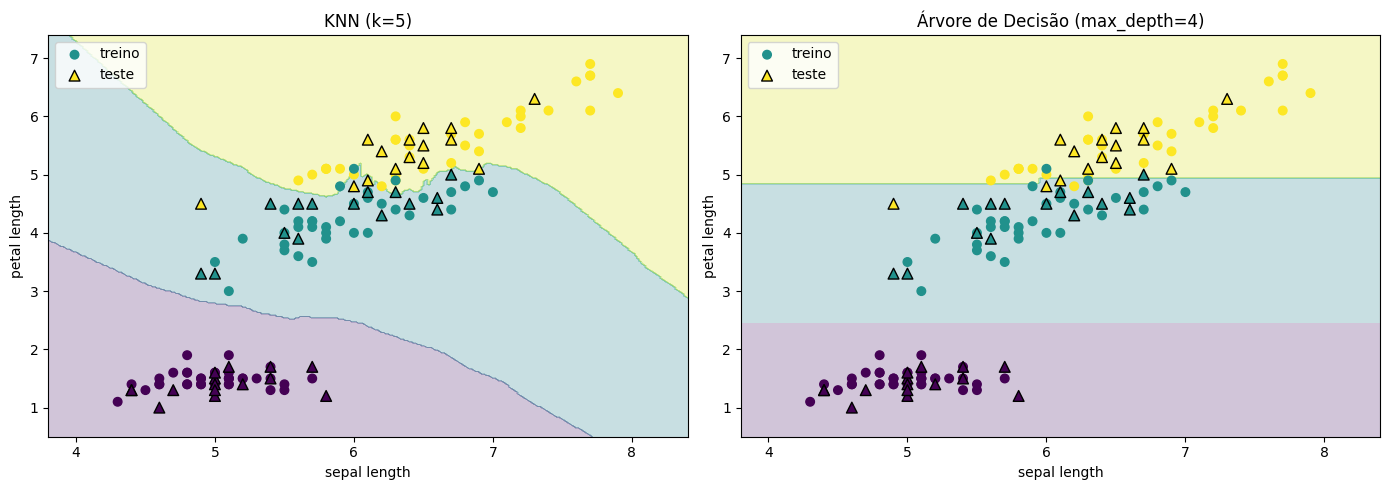

In [25]:
# Demonstração guiada: KNN vs. Árvore no mesmo espaço 2D do Iris.
# Usamos Pipeline para que o KNN receba os dados nas unidades originais
# e faça a padronização internamente.

from sklearn.pipeline import Pipeline

X_comp = iris.data[:, [0, 2]]
y_comp = iris.target

Xc2_train, Xc2_test, yc2_train, yc2_test = train_test_split(
    X_comp, y_comp,
    test_size=0.3,
    random_state=42,
    stratify=y_comp
)

knn_comp = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
tree_comp = DecisionTreeClassifier(max_depth=4, random_state=42)

knn_comp.fit(Xc2_train, yc2_train)
tree_comp.fit(Xc2_train, yc2_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_fronteira_decisao(
    knn_comp,
    Xc2_train, yc2_train,
    Xc2_test, yc2_test,
    titulo="KNN (k=5)",
    nomes_features=("sepal length", "petal length"),
    ax=axes[0]
)

plot_fronteira_decisao(
    tree_comp,
    Xc2_train, yc2_train,
    Xc2_test, yc2_test,
    titulo="Árvore de Decisão (max_depth=4)",
    nomes_features=("sepal length", "petal length"),
    ax=axes[1]
)

plt.tight_layout()
plt.show()


**Sua resposta (Exercício 9c):**

---

## ✅ RESPOSTA — Exercício 9 (a), (b) e (c)

**(a) Medições no Wine** (124 amostras de treino, 54 de teste, 13 features; média de 20 repetições):

| modelo | acurácia (teste) | `fit` | `predict` |
|:--|--:|--:|--:|
| KNN ($k = 13$, com padronização) | **0,9815** | ≈ 0,7 ms | ≈ 0,77 ms |
| Árvore (`max_depth=3`, `min_samples_leaf=5`) | 0,9630 | ≈ 0,6 ms | **≈ 0,07 ms** |

A diferença de acurácia é de **um** exemplo em 54 (1,85 p.p.) — nada, diante do desvio de 0,031 entre dobras medido no Exercício 3. Os dois modelos são empatados em qualidade neste dataset. O que **não** empata é o tempo de predição: a árvore é **cerca de uma ordem de grandeza mais rápida** (10× a 14× entre execuções — o valor exato oscila com a máquina, a razão não), e essa diferença é estrutural, não ruído de medição.

**(b) Geometria.** O gráfico da célula anterior mostra a diferença essencial: a fronteira do KNN é **curva e irregular**, acompanhando a densidade local dos pontos (ela é um Voronoi suavizado por $k$); a da árvore é feita de **retângulos**, com bordas estritamente horizontais e verticais, porque cada split é da forma `feature ≤ limiar` e portanto **perpendicular a um eixo**. Consequência prática: a árvore precisa de uma escada de muitos splits para aproximar uma fronteira diagonal, enquanto o KNN a representa naturalmente — mas o KNN não consegue dizer *por que* decidiu.

**(c) Quando eu escolheria cada um.**

**Escolho a árvore quando:**

- **a latência de predição importa.** Predição em $O(\text{profundidade})$ — aqui, 3 comparações — contra $O(n \cdot d)$ do KNN ingênuo. Em um serviço com SLA de milissegundos ou em um dispositivo embarcado, isso decide. E a árvore não precisa **carregar o conjunto de treino em memória** para predizer: só a estrutura;
- **o modelo precisa ser auditado ou explicado.** "Raio máximo ≤ 16,8 e contorno regular ⇒ benigno" é uma frase que um médico, um auditor ou um juiz entende. O KNN só sabe dizer "porque seus 13 vizinhos mais parecidos eram assim";
- **as features têm escalas ou tipos heterogêneos.** A árvore é invariante a transformações monotônicas de cada feature: não exige padronização e lida com variáveis ordinais sem pré-processamento. O KNN **depende** da escala para definir vizinhança — veja a célula 1.5, onde padronizar mudou a acurácia no Wine;
- **há muitas features irrelevantes.** No Exercício 10 isso fica brutal: com 100 features (2 informativas), o KNN cai para **0,5889** e a árvore se mantém em **0,8778**.

**Escolho o KNN quando:**

- **a fronteira real é curva ou multimodal** e não quero impor cortes axiais. O KNN não assume forma nenhuma: com dados suficientes, ele converge para a regra de Bayes;
- **os dados crescem continuamente e o retreino incomoda.** "Treinar" é concatenar linhas — ideal para sistemas de recomendação por similaridade ou busca por vizinhos, onde o catálogo muda toda hora e refazer uma árvore a cada inserção seria desperdício;
- **o problema é de poucas dimensões e muitos dados**, situação em que a distância ainda é informativa e estruturas como KD-Tree ou Ball-Tree derrubam o custo de busca;
- **quero um baseline honesto e rápido de escrever** para saber se vale investir em algo mais sofisticado.

**Manutenção — o critério que costuma ser esquecido.** O KNN carrega o conjunto de treino **para produção**: o artefato cresce com os dados, e se os dados têm informação pessoal, o modelo *é* um banco de dados pessoal (com implicações de LGPD e de direito ao esquecimento). A árvore descarta os dados depois do `fit`. Em troca, a árvore é **instável**: trocar alguns exemplos pode mudar o split da raiz e produzir uma árvore visualmente muito diferente, o que gera desconfiança em quem revisa o modelo periodicamente. Em produção real, raramente se usa uma árvore única — usa-se um ensemble (Random Forest, Gradient Boosting), que troca a interpretabilidade pela estabilidade e pela acurácia.

**Neste caso concreto (Wine):** ficaria com a **árvore**. Empate em acurácia, predição ~10× mais rápida, nenhuma dependência de padronização e uma regra legível com 3 perguntas. Pagar 1,85 p.p. (um exemplo) por tudo isso é um bom negócio.

---

### Exercício 10 — Desafio (opcional, vale ponto extra)

**Maldição da dimensionalidade e o KNN.** Gere datasets sintéticos com `sklearn.datasets.make_classification` com número crescente de features (2, 5, 10, 20, 50, 100 — mantendo `n_informative` fixo em 2) e plote a acurácia de teste do KNN (k=5, normalizado) e da Árvore de Decisão em função do número de features. Explique o fenômeno observado: por que as distâncias se tornam "menos informativas" em alta dimensão?

In [ ]:
# ✅ RESPOSTA — Exercício 10 (desafio): maldição da dimensionalidade
from sklearn.datasets import make_classification

n_features_lista = [2, 5, 10, 20, 50, 100]
acc_knn, acc_tree, contraste = [], [], []

for n_feat in n_features_lista:
    # n_informative fixo em 2: toda feature extra é RUÍDO puro
    Xs, ys = make_classification(n_samples=600, n_features=n_feat, n_informative=2,
                                 n_redundant=0, n_repeated=0, n_clusters_per_class=1,
                                 random_state=42)
    Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3,
                                                  random_state=42, stratify=ys)

    knn_d = Pipeline([("scaler", StandardScaler()),
                      ("knn", KNeighborsClassifier(n_neighbors=5))]).fit(Xs_tr, ys_tr)
    tree_d = DecisionTreeClassifier(max_depth=5, random_state=42).fit(Xs_tr, ys_tr)
    acc_knn.append(accuracy_score(ys_te, knn_d.predict(Xs_te)))
    acc_tree.append(accuracy_score(ys_te, tree_d.predict(Xs_te)))

    # Medida do colapso do contraste: razão entre o vizinho mais longe e o mais perto
    esc = StandardScaler().fit(Xs_tr)
    A, B = esc.transform(Xs_te), esc.transform(Xs_tr)
    D = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))
    contraste.append(float((D.max(axis=1) / D.min(axis=1)).mean()))

print(f"{'p':>4} | {'KNN':>7} | {'Árvore':>7} | {'d_max/d_min médio':>18}")
print("-" * 45)
for p, a, b, c in zip(n_features_lista, acc_knn, acc_tree, contraste):
    print(f"{p:>4} | {a:>7.4f} | {b:>7.4f} | {c:>18.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
axes[0].plot(n_features_lista, acc_knn, marker="o", label="KNN (k=5, padronizado)")
axes[0].plot(n_features_lista, acc_tree, marker="s", label="Árvore (max_depth=5)")
axes[0].axhline(0.5, ls=":", color="gray", label="acaso (2 classes)")
axes[0].set_xscale("log"); axes[0].set_xticks(n_features_lista)
axes[0].set_xticklabels(n_features_lista)
axes[0].set_xlabel("nº de features (apenas 2 informativas)")
axes[0].set_ylabel("acurácia no teste"); axes[0].set_ylim(0.4, 1.0)
axes[0].set_title("Maldição da dimensionalidade"); axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(n_features_lista, contraste, marker="D", color="#eb6834")
axes[1].axhline(1.0, ls=":", color="gray", label="sem contraste (todos equidistantes)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xticks(n_features_lista); axes[1].set_xticklabels(n_features_lista)
axes[1].set_xlabel("nº de features")
axes[1].set_ylabel("d_max / d_min (média)")
axes[1].set_title("O contraste entre distâncias colapsa"); axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\nKNN: {acc_knn[0]:.4f} (p=2)  ->  {acc_knn[-1]:.4f} (p=100):  "
      f"queda de {(acc_knn[0]-acc_knn[-1])*100:.1f} pontos")
print(f"Árvore: {acc_tree[0]:.4f} -> {acc_tree[-1]:.4f}:  queda de "
      f"{(acc_tree[0]-acc_tree[-1])*100:.1f} pontos")

**Sua resposta (Exercício 10):**

---

## ✅ RESPOSTA — Exercício 10 (desafio)

**Resultados.** 600 amostras, **sempre 2 features informativas**; todas as demais são ruído gaussiano independente do rótulo:

| nº de features | KNN ($k=5$, padronizado) | Árvore (`max_depth=5`) | $d_{\max}/d_{\min}$ médio |
|--:|--:|--:|--:|
| 2 | **0,9500** | 0,9333 | 109,92 |
| 5 | 0,9444 | 0,9389 | 8,92 |
| 10 | 0,8667 | 0,9444 | 3,85 |
| 20 | 0,7611 | 0,9333 | 2,41 |
| 50 | 0,6833 | 0,8722 | 1,70 |
| 100 | **0,5889** | **0,8778** | **1,45** |

O KNN perde **36 pontos percentuais** e chega perto do acaso (0,5); a árvore perde 5,6 pontos e continua útil. **A informação disponível é exatamente a mesma nos dois extremos** — duas features informativas — então toda a degradação do KNN vem de como ele a usa.

**Por que as distâncias ficam "menos informativas" — o mecanismo.** A distância euclidiana **soma** as contribuições de todas as features:

$$d(a,b)^2 = \underbrace{\sum_{j \in \text{informativas}} (a_j - b_j)^2}_{\text{2 termos: o sinal}} \;+\; \underbrace{\sum_{j \in \text{ruído}} (a_j - b_j)^2}_{p-2 \text{ termos: o ruído}}.$$

Com features padronizadas e independentes, cada termo de ruído contribui, em média, com $2$ (a variância de uma diferença de duas variáveis de variância 1). Então o ruído aporta $\approx 2(p-2)$ ao quadrado da distância, enquanto o sinal aporta uma quantidade **fixa**. Em $p = 100$, 98 dos 100 termos são ruído: a distância mede essencialmente **quanto dois pontos diferem em coordenadas que nada têm a ver com a classe**. O vizinho "mais próximo" passa a ser um ponto sorteado quase ao acaso.

A coluna da direita quantifica isso diretamente. A razão entre a distância ao ponto mais **longe** e ao mais **perto** cai de **110** para **1,45**: em 100 dimensões, o vizinho mais próximo está a apenas 45% menos distância que o mais afastado de todos. Esse é o resultado clássico de Beyer et al. (1999) — sob condições amplas, $d_{\max}/d_{\min} \to 1$ quando $p \to \infty$. Quando todos estão praticamente **equidistantes**, "os $k$ mais próximos" deixa de ser um conceito com conteúdo, e o KNN vira um sorteio. Some-se o efeito de volume: para capturar uma fração fixa $f$ do espaço, o raio da vizinhança precisa ser $f^{1/p}$ — em $p=100$, cobrir 1% do volume exige um raio de $0{,}01^{1/100} \approx 0{,}955$, isto é, **quase todo o cubo**. Não existe mais vizinhança "local".

**Por que a árvore resiste.** Ela não usa distância: em cada nó testa **uma** feature por vez e escolhe a que maximiza o ganho de Gini. Uma feature de ruído produz ganho próximo de zero e simplesmente **não é escolhida**. Com `max_depth=5` a árvore usa no máximo 31 nós e tende a gastá-los nas duas features que realmente separam as classes — ela faz **seleção de variáveis embutida**, de graça. A queda residual de 5,6 pontos vem do risco de, por sorte amostral, alguma feature de ruído produzir ganho espúrio num nó (com 100 candidatas e 420 amostras de treino, uma delas acaba parecendo boa) — é overfitting de seleção, mitigável com poda ou com um ensemble.

**O que fazer na prática quando se precisa de KNN em dimensão alta:** reduzir a dimensão antes (PCA, seleção de features por ganho/mútua informação, embeddings aprendidos), usar métricas aprendidas (*metric learning*) ou pesos por feature, ou aceitar que o modelo baseado em distância é a ferramenta errada e usar um método que selecione variáveis sozinho — árvore, ensemble ou um modelo linear regularizado com L1. A lição transferível: **todo método baseado em distância pressupõe que as dimensões usadas sejam relevantes**, e essa hipótese fica cada vez mais frágil à medida que as colunas se acumulam.

---

# Resumo

## KNN

- aprende por **proximidade**;
- o `fit` praticamente armazena o conjunto de treino;
- a escala das features influencia diretamente as distâncias;
- $k$ pequeno tende a alta variância; $k$ grande tende a maior viés;
- em regressão, a predição pode ser a média dos alvos dos vizinhos;
- em 2D, a fronteira mostra visualmente como as regiões de vizinhança determinam a classe.

## Árvores de decisão

- são modelos **não paramétricos** que aprendem uma estrutura de regras;
- escolhem splits que reduzem a impureza (classificação) ou o erro (regressão);
- não dependem de padronização para splits usuais;
- árvores pequenas são interpretáveis;
- profundidade excessiva favorece *overfitting*;
- em 2D, seus cortes por limiar produzem regiões alinhadas aos eixos.

## O que deve ficar conceitualmente claro

Mais importante do que memorizar APIs é conseguir responder:

1. **Que hipótese de similaridade o KNN faz?**
2. **Por que padronização altera seus vizinhos?**
3. **Como $k$ controla a complexidade efetiva do modelo?**
4. **O que uma fronteira de decisão representa?**
5. **Como Gini/entropia ajudam uma árvore a escolher splits?**
6. **Por que profundidade controla a complexidade da árvore?**
7. **Que trade-offs práticos diferenciam KNN e árvore?**

---

## Entrega

📅 **Entregue até 02/10** o notebook `.ipynb` **executado**.


## Referências

- scikit-learn: *Nearest Neighbors* e *Decision Trees*;
- Géron, A. *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow*;
- James, Witten, Hastie, Tibshirani. *An Introduction to Statistical Learning*.
